In [1]:
import os
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/hausa_news_project"
os.chdir(PROJECT_DIR)

needed = ["train.csv", "val.csv", "test.csv", "labels.json", "results.json"]
print("Missing core files:", [f for f in needed if not os.path.exists(f)] or "none")
print("Error files:", [f for f in os.listdir(".") if f.endswith("_errors.csv")])
print("Transformer prediction files:", len(os.listdir("preds")) if os.path.exists("preds") else 0)

Mounted at /content/drive
Missing core files: none
Error files: ['neural_errors.csv', 'baseline_errors.csv', 'transformer_errors.csv']
Transformer prediction files: 14


In [2]:
import json, glob, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                             f1_score, accuracy_score)
SEED = 42

train = pd.read_csv("train.csv"); val = pd.read_csv("val.csv"); test = pd.read_csv("test.csv")
meta = json.load(open("labels.json"))
id2label = {int(k): v for k, v in meta["id2label"].items()}
label_names = [id2label[i] for i in range(len(id2label))]
label2id = {l: i for i, l in enumerate(label_names)}
K = len(label_names)
y_test = test["label_id"].values
test["n_words"] = test["text_clean"].str.split().str.len()



def preds_from_errors(path):
    err = pd.read_csv(path)
    m = dict(zip(err["text"], err["pred"]))
    return np.array([label2id[m.get(t, l)] for t, l in zip(test["text_clean"], test["label_name"])])

PREDS = {}
for name, f in [("Baseline TF-IDF+SVM", "baseline_errors.csv"), ("Best neural", "neural_errors.csv")]:
    if os.path.exists(f): PREDS[name] = preds_from_errors(f)
    else: print("Missing", f, "-> skipping", name)


runs = sorted([(float(np.load(f)["val_f1"]), str(np.load(f)["name"]), f)
               for f in glob.glob("preds/*.npz") if not str(np.load(f)["name"]).startswith("SEED")],
              reverse=True)
probs = None
if runs:
    _, tname, tfile = runs[0]
    logits = np.load(tfile)["test_logits"]
    probs = np.exp(logits - logits.max(1, keepdims=True)); probs /= probs.sum(1, keepdims=True)
    PREDS["Best transformer"] = logits.argmax(1)
    print("Transformer run used:", tname)

BEST = "Best transformer" if "Best transformer" in PREDS else list(PREDS)[-1]
print("Model analysed in detail:", BEST, "\n")
for n, p in PREDS.items():
    print(f"{n:22s} acc={accuracy_score(y_test, p):.3f}  macro-F1={f1_score(y_test, p, average='macro'):.3f}")

Transformer run used: AfroXLMR-base | head256 | lr1e-05
Model analysed in detail: Best transformer 

Baseline TF-IDF+SVM    acc=0.887  macro-F1=0.875
Best neural            acc=0.879  macro-F1=0.864
Best transformer       acc=0.906  macro-F1=0.898


               Baseline TF-IDF+SVM  Best neural  Best transformer  support
business                     0.774        0.715             0.792       80
entertainment                0.904        0.895             0.914      100
health                       0.932        0.914             0.910       99
politics                     0.867        0.864             0.905      100
religion                     0.909        0.911             0.941       99
sports                       0.985        0.995             0.990      100
technology                   0.757        0.754             0.835       59


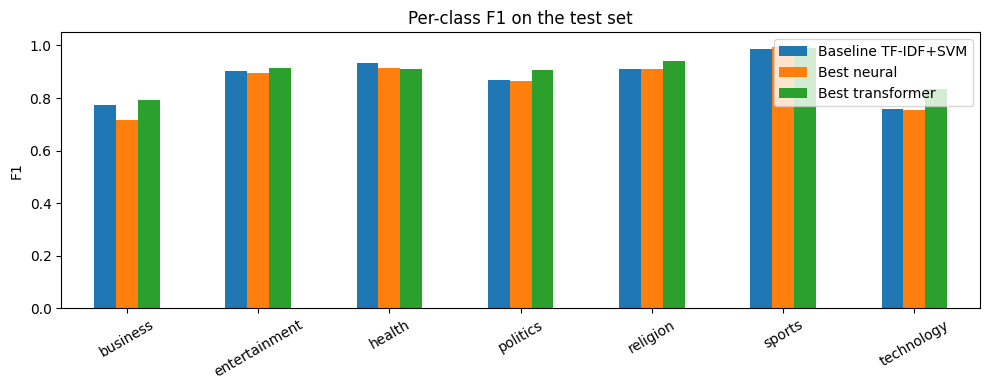

In [3]:
rows = {}
for n, p in PREDS.items():
    _, _, f, _ = precision_recall_fscore_support(y_test, p, labels=range(K), zero_division=0)
    rows[n] = f
pc = pd.DataFrame(rows, index=label_names).round(3)
pc["support"] = np.bincount(y_test, minlength=K)
print(pc)

pc.drop(columns="support").plot(kind="bar", figsize=(10, 4))
plt.ylabel("F1"); plt.title("Per-class F1 on the test set"); plt.ylim(0, 1.05)
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig("per_class_f1.png", dpi=150); plt.show()

In [4]:
cm = confusion_matrix(y_test, PREDS[BEST], labels=range(K))
pairs = pd.DataFrame([(label_names[i], label_names[j], cm[i, j])
                      for i in range(K) for j in range(K) if i != j and cm[i, j] > 0],
                     columns=["true", "predicted", "count"]).sort_values("count", ascending=False)
print(f"Total errors for {BEST}: {int(pairs['count'].sum())} of {len(y_test)}")
print(pairs.head(10).to_string(index=False))

Total errors for Best transformer: 60 of 637
         true  predicted  count
     business     health      6
     business   religion      6
     politics   business      6
   technology   business      6
       health   business      4
entertainment technology      4
     business   politics      3
     religion   politics      3
entertainment   politics      2
entertainment     health      2


In [5]:
test["len_bin"] = pd.qcut(test["n_words"], 4, duplicates="drop")
wrong = pd.DataFrame({n: (p != y_test) for n, p in PREDS.items()})

by_len = wrong.assign(len_bin=test["len_bin"]).groupby("len_bin", observed=True).mean() * 100
by_len["n_articles"] = test.groupby("len_bin", observed=True).size()
print("Error rate (%) by article length (words):")
print(by_len.round(1))

print("\nHow many models get each article wrong:")
print(wrong.sum(axis=1).value_counts().sort_index().rename("n_articles"))

if "Best transformer" in PREDS and "Baseline TF-IDF+SVM" in PREDS:
    print("\nTransformer wrong vs baseline wrong:")
    print(pd.crosstab(wrong["Best transformer"], wrong["Baseline TF-IDF+SVM"],
                      rownames=["transformer wrong"], colnames=["baseline wrong"]))

Error rate (%) by article length (words):
                 Baseline TF-IDF+SVM  Best neural  Best transformer  \
len_bin                                                               
(5.999, 204.0]                  13.1         11.9               8.8   
(204.0, 373.0]                   8.1         11.9              10.0   
(373.0, 643.0]                   8.9          9.5               7.0   
(643.0, 3260.0]                 15.1         15.1              11.9   

                 n_articles  
len_bin                      
(5.999, 204.0]          160  
(204.0, 373.0]          160  
(373.0, 643.0]          158  
(643.0, 3260.0]         159  

How many models get each article wrong:
0    521
1     50
2     39
3     27
Name: n_articles, dtype: int64

Transformer wrong vs baseline wrong:
baseline wrong     False  True 
transformer wrong              
False                538     39
True                  27     33


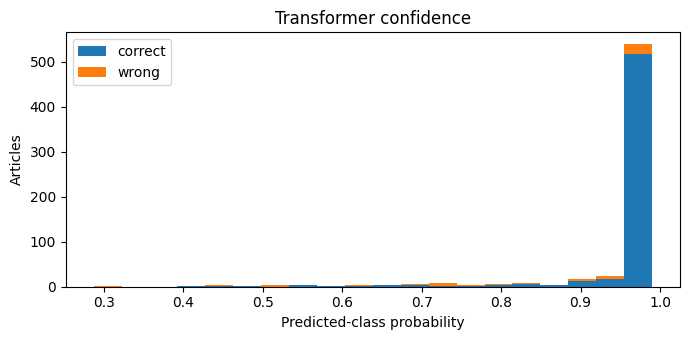

              n  n_wrong  error_rate
conf_bin                            
(0.0, 0.5]    8        5       0.625
(0.5, 0.7]   20        9       0.450
(0.7, 0.9]   37       16       0.432
(0.9, 1.0]  572       30       0.052

30 confident errors (p > 0.9). Read these: some may be label noise.

[1] true=business | pred=politics | p=0.95
    Abin da ya kamata ku sani game da kama gwamnan CBN Emefiele. Rahotannin da ke kara-kaina a wasu kafafen yada labarai na cewa hukumar tsaron farin kaya na shirin kama gwamnan babban bankin Najeriya CBN, Godwin Emefiele. Wata babbar kotu a Abuja babban birnin kasar ta yi watsi da bukatar DSS ta kamawa 

[5] true=business | pred=health | p=0.97
    Haƙar ma'adinai a Niger: 'Na rasa 'ya'yana uku saboda karya doka'. Wani mutum mai suna Nuhu da ke zaune a ƙauyen Shikira na jihar Naija a arewacin Najeriya na cikin jimami, shekara huɗu bayan gubar dalma ta kashe 'ya'yansa uku. Wata rana ya tashi daga barci, sai ya ga 'yarsa ta farko na cikin wani h 

[11] true=

In [6]:
if probs is not None and BEST == "Best transformer":
    conf = probs.max(1); wr = PREDS[BEST] != y_test
    plt.figure(figsize=(7, 3.5))
    plt.hist([conf[~wr], conf[wr]], bins=20, stacked=True, label=["correct", "wrong"])
    plt.xlabel("Predicted-class probability"); plt.ylabel("Articles"); plt.legend()
    plt.title("Transformer confidence"); plt.tight_layout()
    plt.savefig("confidence_hist.png", dpi=150); plt.show()

    b = pd.cut(conf, [0, .5, .7, .9, 1.0])
    print(pd.DataFrame({"conf_bin": b, "wrong": wr}).groupby("conf_bin", observed=True)["wrong"]
          .agg(n="count", n_wrong="sum", error_rate="mean").round(3))

    hi = np.where(wr & (conf > 0.9))[0]
    print(f"\n{len(hi)} confident errors (p > 0.9). Read these: some may be label noise.\n")
    for i in hi[:10]:
        print(f"[{i}] true={label_names[y_test[i]]} | pred={label_names[PREDS[BEST][i]]} | p={conf[i]:.2f}")
        print("   ", test['text_clean'][i][:300].replace("\n", " "), "\n")
else:
    print("No transformer predictions found, skipping.")

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vec = TfidfVectorizer(lowercase=True, min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(train["text_clean"])
lr = LogisticRegression(max_iter=2000, C=10, random_state=SEED).fit(Xtr, train["label_id"])
Xte = vec.transform(test["text_clean"])
vocab = np.array(vec.get_feature_names_out())

print("Top words per class (logistic regression weights):")
for i, l in enumerate(label_names):
    print(f"  {l:14s}", ", ".join(vocab[np.argsort(lr.coef_[i])[::-1][:12]]))

def drivers(idx, cls, k=5):
    contrib = Xte[idx].multiply(lr.coef_[cls]).toarray().ravel()
    top = np.argsort(contrib)[::-1][:k]
    return ", ".join(vocab[t] for t in top if contrib[t] > 0)

Top words per class (logistic regression weights):
  business       tattalin, naira, man, sana, talauci, arzikin, farashin, kuɗi, fetur, bankin, dala, kudin
  entertainment  fim, kannywood, fina, waka, waƙar, sarauniya, hausa, finan, elizabeth, hotunan, bakin, finai
  health         cutar, lafiya, coronavirus, likitoci, lafiyar, kamu, mutum, kamuwa, likita, ciwon, shan, asibitin
  politics       jam, gwamnan, zaben, iyyar, najeriya, buhari, takarar, apc, shugaban, zabe, pdp, jihar
  religion       musulunci, addinin, musulmi, sheikh, musulmai, malamanku, malamin, masallacin, addini, annabi, ani, kirsimeti
  sports         wasan, gasar, buga, wasa, kwallon, kofin, league, dan, kakar, kwallo, qatar, united
  technology     kamfanin, amfani, intanet, fasahar, fasaha, manhajar, wayoyin, duniyar, amurka, facebook, sararin, samaniya


In [8]:
err_idx = np.where(PREDS[BEST] != y_test)[0]
rng = np.random.default_rng(SEED)
sample = sorted(rng.choice(err_idx, size=min(40, len(err_idx)), replace=False))

rows = []
for i in sample:
    t, p = y_test[i], PREDS[BEST][i]
    rows.append({"test_idx": i, "true": label_names[t], "pred": label_names[p],
                 "confidence": round(float(probs[i].max()), 3) if probs is not None and BEST == "Best transformer" else None,
                 "n_words": int(test["n_words"][i]),
                 "words_for_pred_class": drivers(i, p), "words_for_true_class": drivers(i, t),
                 "text": test["text_clean"][i][:500],
                 "error_type": "", "notes": ""})
pd.DataFrame(rows).to_csv("error_annotation.csv", index=False)
print(f"Saved error_annotation.csv with {len(rows)} errors")

Saved error_annotation.csv with 40 errors


In [10]:
ann = pd.read_csv("error_annotation.csv", dtype={"error_type": object, "notes": object})
TYPES = {"1": "label ambiguity / questionable label",
         "2": "multi-topic digest or listicle",
         "3": "topic-keyword confusion",
         "4": "very short text",
         "5": "unseen entities / vocabulary",
         "6": "truncation (key info after 256 tokens)",
         "7": "orthographic variation",
         "8": "other"}
print(TYPES)
for i, r in ann.iterrows():
    if isinstance(r["error_type"], str) and r["error_type"].strip():
        continue
    print(f"\n[{r['test_idx']}] true={r['true']} pred={r['pred']} conf={r['confidence']} words={r['n_words']}")
    print("pred-class drivers:", r["words_for_pred_class"], "| true-class drivers:", r["words_for_true_class"])
    print(r["text"][:500])
    k = input("type (1-8, q to stop): ").strip()
    if k == "q": break
    ann.loc[i, "error_type"] = TYPES.get(k, "other")
    ann.loc[i, "notes"] = input("short note: ")
    ann.to_csv("error_annotation.csv", index=False)





{'1': 'label ambiguity / questionable label', '2': 'multi-topic digest or listicle', '3': 'topic-keyword confusion', '4': 'very short text', '5': 'unseen entities / vocabulary', '6': 'truncation (key info after 256 tokens)', '7': 'orthographic variation', '8': 'other'}

[2] true=business pred=entertainment conf=0.721 words=837
pred-class drivers: bakin, fito, kawo, zamanin, kabilu | true-class drivers: talauci, tattalin, arzikin, cike, kasar
Elisa Loncón: Matar da ta samu ɗaukakar rubuta tsarin mulkin ƙasa bayan fama da talauci. A shekarun 1970 lokacin da Elisa Loncón ke tasowa, sai ta yi tafiyar mil 8 kafin ta isa makaranta. Iyayenta 'yan asalin yankin Mapuche ne na kasar Chile, wadanda ke rayuwa cikin bakin talauci a wani kauye da ke kudancin yankin Araucanía. Babu wanda ya ke taimakon kai ta makaranta, yawancin lokuta da kafa take takawa ta hanya mai cike da datti. Mahaifiyarta aikatau ta ke yi a gidan masu kudi, sannan ta na kau
type (1-8, q to stop): 1
short note: Label looks wron

40 of 40 errors annotated

error_type
other                                     33
label ambiguity / questionable label       1
multi-topic digest or listicle             1
topic-keyword confusion                    1
very short text                            1
unseen entities / vocabulary               1
truncation (key info after 256 tokens)     1
orthographic variation                     1
Name: count, dtype: int64


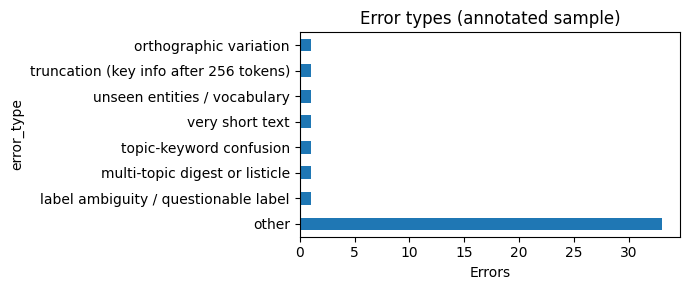


[other] true=business pred=religion
  An sako ƙarin fasinjojin Abuja-Kaduna bakwai. Maharan jirgin ƙasan Abuja-Kaduna sun sako ƙarin mutum bakwai daga cikin fasinjojin da suka sace a harin da suka kai kan jirgin a watan Maris. Mai shiga tsakani a sasantawa tsakanin maharan da dangin fasi

[label ambiguity / questionable label] true=business pred=entertainment
  Elisa Loncón: Matar da ta samu ɗaukakar rubuta tsarin mulkin ƙasa bayan fama da talauci. A shekarun 1970 lokacin da Elisa Loncón ke tasowa, sai ta yi tafiyar mil 8 kafin ta isa makaranta. Iyayenta 'yan asalin yankin Mapuche ne na kasar Chile, wadanda

[multi-topic digest or listicle] true=business pred=health
  Haƙar ma'adinai a Niger: 'Na rasa 'ya'yana uku saboda karya doka'. Wani mutum mai suna Nuhu da ke zaune a ƙauyen Shikira na jihar Naija a arewacin Najeriya na cikin jimami, shekara huɗu bayan gubar dalma ta kashe 'ya'yansa uku. Wata rana ya tashi dag

[topic-keyword confusion] true=business pred=health
  NAPTIP ta gargaɗ

In [11]:
ann = pd.read_csv("error_annotation.csv")
done = ann[ann["error_type"].notna() & (ann["error_type"].astype(str).str.strip() != "")]
print(f"{len(done)} of {len(ann)} errors annotated\n")

if len(done) > 0:
    counts = done["error_type"].value_counts()
    print(counts)
    counts.plot(kind="barh", figsize=(7, 3)); plt.xlabel("Errors"); plt.title("Error types (annotated sample)")
    plt.tight_layout(); plt.savefig("error_types.png", dpi=150); plt.show()
    for et in counts.index:
        r = done[done["error_type" ] == et].iloc[0]
        print(f"\n[{et}] true={r['true']} pred={r['pred']}\n  {r['text'][:250]}")
else:
    print("To see results and plots, please open 'error_annotation.csv', fill in some 'error_type' values, and run this cell again.")

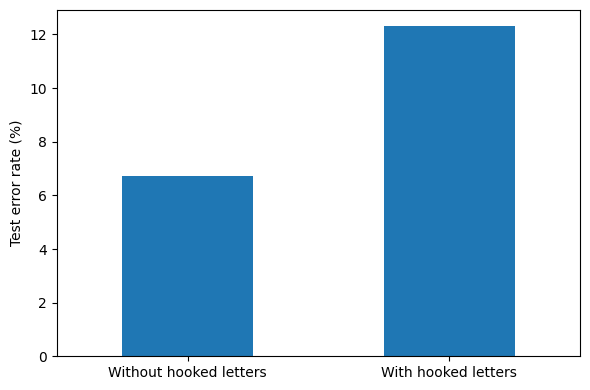

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import re


hook = re.compile("[ɓɗƙƴƁƊƘƳ]")
test["has_hooked"] = test["text_clean"].apply(lambda t: bool(hook.search(t)))

wrong = pd.DataFrame({n: (p != y_test) for n, p in PREDS.items()})

rates = wrong["Best transformer"].groupby(test["has_hooked"]).mean() * 100
rates.index = ["Without hooked letters", "With hooked letters"]
ax = rates.plot(kind="bar", rot=0, figsize=(6, 4)); ax.set_ylabel("Test error rate (%)")
plt.tight_layout(); plt.savefig("hooked_letter_error_rate.png", dpi=200); plt.show()

In [13]:
hook = re.compile("[ɓɗƙƴƁƊƘƳ]")
test["has_hooked"] = test["text_clean"].apply(lambda t: bool(hook.search(t)))
test["ascii_apos_y"] = test["text_clean"].str.contains(r"(?:^|\s)['’‘]y", regex=True)

for col in ["has_hooked", "ascii_apos_y"]:
    g = wrong.assign(group=test[col]).groupby("group").mean() * 100
    g["n_articles"] = test.groupby(col).size()
    print(f"\nError rate (%) by {col}:")
    print(g.round(1))


Error rate (%) by has_hooked:
       Baseline TF-IDF+SVM  Best neural  Best transformer  n_articles
group                                                                
False                  7.9         10.1               6.7         328
True                  14.9         14.2              12.3         309

Error rate (%) by ascii_apos_y:
       Baseline TF-IDF+SVM  Best neural  Best transformer  n_articles
group                                                                
False                  9.6          9.0               5.1         334
True                  13.2         15.5              14.2         303


In [14]:
from scipy.stats import chi2_contingency
tab = pd.crosstab(test["has_hooked"], wrong["Best transformer"])
print(tab)
print("chi-square p-value:", round(chi2_contingency(tab)[1], 3))

Best transformer  False  True 
has_hooked                    
False               306     22
True                271     38
chi-square p-value: 0.023


Run used: AfroXLMR-base | head256 | lr1e-05 | errors: 60
               precision    recall  f1-score   support

     business      0.797     0.787     0.792        80
entertainment      0.928     0.900     0.914       100
       health      0.901     0.919     0.910        99
     politics      0.901     0.910     0.905       100
     religion      0.922     0.960     0.941        99
       sports      0.990     0.990     0.990       100
   technology      0.857     0.814     0.835        59

     accuracy                          0.906       637
    macro avg      0.900     0.897     0.898       637
 weighted avg      0.905     0.906     0.905       637

weighted F1: 0.9055


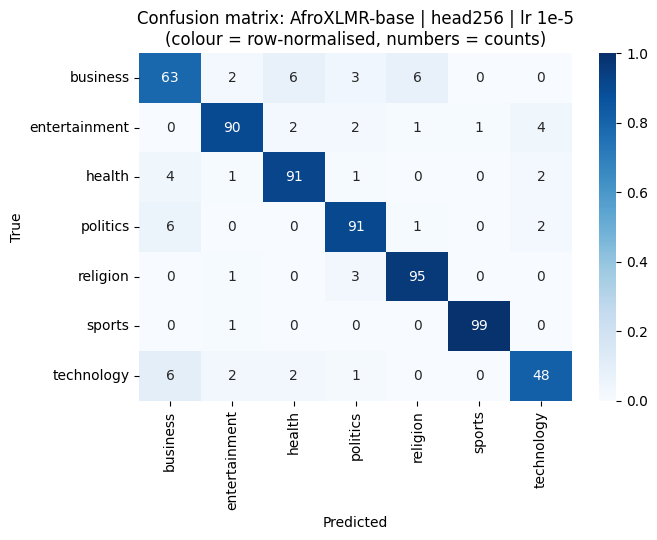

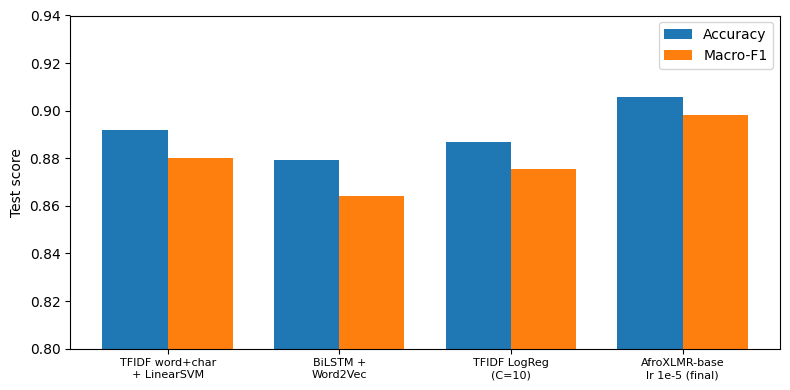

U+FEFF articles: 50 (7.8%)
error rate with: 4.0%  without: 9.9%
chi-square p: 0.265
apostrophe-y chi-square p: 0.0001
majority acc / macro-F1: 0.157 0.039


In [16]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.dummy import DummyClassifier
from scipy.stats import chi2_contingency

pred = PREDS["Best transformer"]; wr = pred != y_test
print("Run used:", tname, "| errors:", int(wr.sum()))


print(classification_report(y_test, pred, target_names=label_names, digits=3))
print("weighted F1:", round(f1_score(y_test, pred, average="weighted"), 4))


cm = confusion_matrix(y_test, pred, labels=range(K))
plt.figure(figsize=(7, 5.5))
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt="d", cmap="Blues",
            xticklabels=label_names, yticklabels=label_names, vmin=0, vmax=1)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion matrix: AfroXLMR-base | head256 | lr 1e-5\n(colour = row-normalised, numbers = counts)")
plt.tight_layout(); plt.savefig("confusion_final.png", dpi=150); plt.show()


names = ["TFIDF word+char\n+ LinearSVM", "BiLSTM +\nWord2Vec", "TFIDF LogReg\n(C=10)", "AfroXLMR-base\nlr 1e-5 (final)"]
acc = [0.8917, 0.8791, 0.8870, accuracy_score(y_test, pred)]
mf1 = [0.8803, 0.8640, 0.8753, f1_score(y_test, pred, average="macro")]
x = np.arange(4); w = 0.38
plt.figure(figsize=(8, 4))
plt.bar(x - w/2, acc, w, label="Accuracy"); plt.bar(x + w/2, mf1, w, label="Macro-F1")
plt.xticks(x, names, fontsize=8); plt.ylim(0.80, 0.94); plt.ylabel("Test score"); plt.legend()
plt.tight_layout(); plt.savefig("test_scores_final.png", dpi=150); plt.show()


zw = test["text_clean"].str.contains("\ufeff", regex=False)
print("U+FEFF articles:", int(zw.sum()), f"({zw.mean()*100:.1f}%)")
print(f"error rate with: {wr[zw].mean()*100:.1f}%  without: {wr[~zw].mean()*100:.1f}%")
print("chi-square p:", round(chi2_contingency(pd.crosstab(zw, wr))[1], 3))


ap = test["text_clean"].str.contains(r"(?:^|\s)['’‘]y", regex=True)
print("apostrophe-y chi-square p:", round(chi2_contingency(pd.crosstab(ap, wr))[1], 4))


d = DummyClassifier(strategy="most_frequent").fit(train["text_clean"], train["label_id"])
mp = d.predict(test["text_clean"])
print("majority acc / macro-F1:", round(accuracy_score(y_test, mp), 3), round(f1_score(y_test, mp, average="macro"), 3))

In [17]:
def boot_diff(a, b, n=2000):
    rng = np.random.default_rng(SEED); N = len(y_test); d = []
    for _ in range(n):
        idx = rng.integers(0, N, N)
        d.append(f1_score(y_test[idx], a[idx], average="macro") - f1_score(y_test[idx], b[idx], average="macro"))
    d = np.array(d)
    return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5)

names = list(PREDS)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        m, lo, hi = boot_diff(PREDS[names[i]], PREDS[names[j]])
        verdict = "difference unlikely to be chance" if lo > 0 or hi < 0 else "CI includes 0, cannot claim a difference"
        print(f"{names[i]} minus {names[j]}: {m:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  -> {verdict}")

Baseline TF-IDF+SVM minus Best neural: +0.011  95% CI [-0.012, +0.034]  -> CI includes 0, cannot claim a difference
Baseline TF-IDF+SVM minus Best transformer: -0.023  95% CI [-0.052, +0.003]  -> CI includes 0, cannot claim a difference
Best neural minus Best transformer: -0.034  95% CI [-0.062, -0.005]  -> difference unlikely to be chance


In [18]:
conf = probs.max(1)
ok = np.where(PREDS[BEST] == y_test)[0]

print("=== High-confidence correct predictions, one per class ===")
for c, lab in enumerate(label_names):
    cand = [i for i in ok[np.argsort(-conf[ok])] if y_test[i] == c][:1]
    for i in cand:
        print(f"\n[{i}] {lab}  p={conf[i]:.2f}  | driving words: {drivers(i, c)}")
        print("   ", test["text_clean"][i][:250])

print("\n=== Correct but low confidence (hard cases the model barely got right) ===")
for i in ok[np.argsort(conf[ok])][:3]:
    print(f"\n[{i}] {label_names[y_test[i]]}  p={conf[i]:.2f}")
    print("   ", test["text_clean"][i][:250])

=== High-confidence correct predictions, one per class ===

[12] business  p=0.98  | driving words: yajin, naira, sana, biyan, aikin
    Mutane na taka sayyada a Kano saboda yajin aikin masu adaidaita sahu. Ku latsa hoton da ke sama don kallon bidiyon: Masu sana'ar tuka babur mai kafa uku na a daidaita sahu ne suka shiga yajin aiki a jihar Kano da ke arewacin Najeriya, kan biyan haraj

[147] entertainment  p=0.99  | driving words: elizabeth, sarauniya, sarki, ii, sarauta
    Rasuwar Sarauniya Elizabeth II: Shekarar faɗi tashi. K﻿awun Elizabeth, Yariman Wales, ya zama sarki a 1936, amma ba shi da ɗa ko ɗaya. S﻿ai Elizabeth wadda ba ta da yayye maza, ta zama ta biyu a kan layin gadon sarauta. A﻿mma kawun nata, ya so ya aur

[273] health  p=0.99  | driving words: cutar, lafiya, kamu, riga, likitoci
    Lafiya Zinariya: Halin da ma'aikatan lafiya ke ciki a annobar cutar korona. Ku latsa lasifikar d ake sama don ssauraron cikakken shirin wanda Habiba Adamu ta gabatar. Wani bincike da aka wa